In [1]:
%matplotlib inline
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [9]:
!{sys.executable} -m pip --version

/bin/bash: line 1: {sys.executable}: command not found


In [115]:
!{sys.executable} -m pip install --user seaborn


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: pip install --upgrade pip


In [2]:
import site, sys
sys.path.append(site.getusersitepackages())
import seaborn as sns
sns.__version__


'0.13.2'

In [3]:
df = pd.read_csv('marksheet.csv')

In [4]:
df.head()

,patient_id,study_id,mri_date,patient_age,psa,psad,prostate_volume,histopath_type,lesion_GS,lesion_ISUP,case_ISUP,case_csPCa,center
0,10000,1000000,2019-07-02,73,7.7,NaN,55.0,MRBx,0+0,0,0,NO,PCNN
1,10001,1000001,2016-05-27,64,8.7,0.09,102.0,NaN,NaN,NaN,0,NO,RUMC
2,10002,1000002,2021-04-18,58,4.2,0.06,74.0,NaN,NaN,NaN,0,NO,ZGT
3,10003,1000003,2019-04-05,72,13.0,NaN,71.5,SysBx,0+0,0,0,NO,ZGT
4,10004,1000004,2020-10-21,67,8.0,0.10,78.0,SysBx+MRBx,"0+0,0+0","0,0",0,NO,RUMC


In [13]:
df.describe()

,patient_id,study_id,patient_age,psa,psad,prostate_volume,case_ISUP
count,1500.000000,1.500000e+03,1500.000000,1460.000000,1049.000000,1473.000000,1500.000000
mean,10735.602667,1.000750e+06,65.595333,11.932397,0.224662,65.045472,0.942000
std,425.311791,4.331570e+02,7.191527,14.939071,0.404288,36.449618,1.333099
min,10000.000000,1.000000e+06,35.000000,0.100000,0.010000,4.000000,0.000000
25%,10368.750000,1.000375e+06,61.000000,5.882500,0.090000,40.000000,0.000000
50%,10733.500000,1.000750e+06,66.000000,8.500000,0.140000,57.000000,0.000000
75%,11101.250000,1.001124e+06,70.000000,13.000000,0.220000,80.000000,2.000000
max,11475.000000,1.001499e+06,92.000000,224.000000,7.000000,308.000000,5.000000


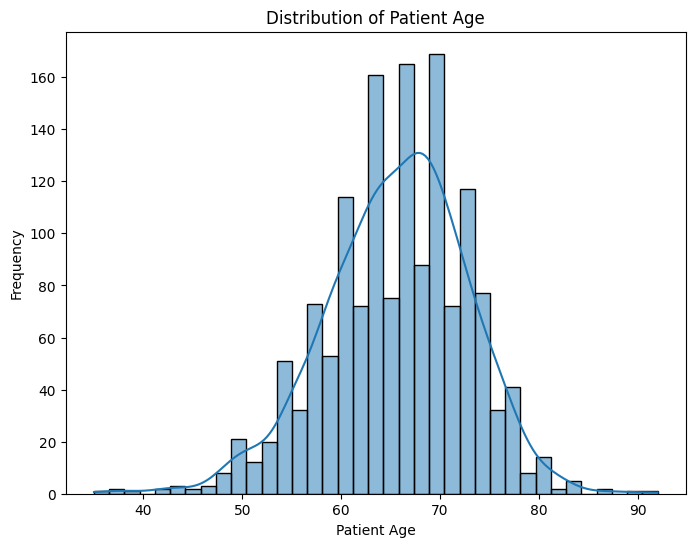

In [15]:
plt.figure(figsize=(8, 6))
sns.histplot(data=df, x='patient_age', kde=True)
plt.title('Distribution of Patient Age')
plt.xlabel('Patient Age')
plt.ylabel('Frequency')
plt.show()

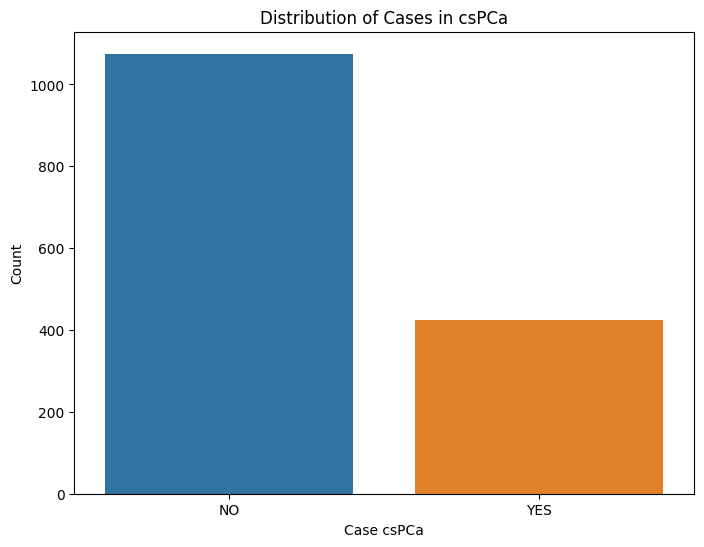

In [16]:
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x='case_csPCa',hue="case_csPCa" )
plt.title('Distribution of Cases in csPCa')
plt.xlabel('Case csPCa')
plt.ylabel('Count')
plt.show()

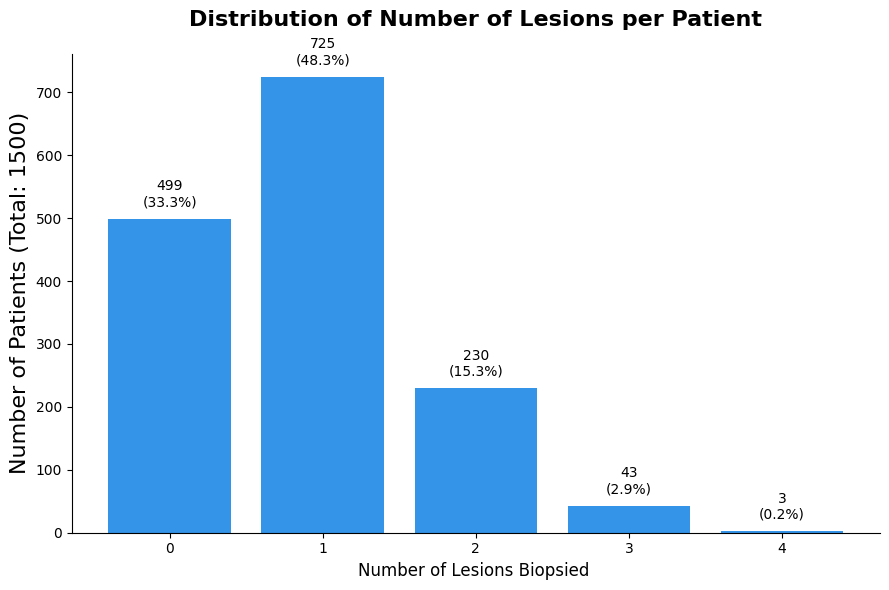

<Figure size 640x480 with 0 Axes>

--- Summary of Lesion Counts ---
Total Patients: 1500
Maximum Lesions in a single patient: 4

Distribution of Lesions:
lesion_count
0    499
1    725
2    230
3     43
4      3
Name: count, dtype: int64


In [17]:
def count_lesions(gs_string):
    """
    Counts the number of lesions by splitting the 'lesion_GS' string by commas.
    Returns 0 if the value is NaN or empty.
    """
    if pd.isna(gs_string) or gs_string == '':
        return 0
    
    # Split by comma and count the parts.
    # The 'N/A' score is not counted.
    try:
        return len([s for s in str(gs_string).split(',') if s != 'N/A'])
    except:
        return 0 # Handle any unexpected parsing errors

# 3. Apply the counting function and calculate the distribution
df['lesion_count'] = df['lesion_GS'].apply(count_lesions)
lesion_distribution = df['lesion_count'].value_counts().sort_index()

# 4. Generate the visualization
# Prepare data for plotting
labels = lesion_distribution.index.astype(str)
sizes = lesion_distribution.values
total_patients = len(df)

# Create the figure and axes
fig, ax = plt.subplots(figsize=(9, 6))

# Plot the distribution as a bar chart
bars = ax.bar(labels, sizes, color='#1E88E5', alpha=0.9)

# Add annotations to the bars
for bar in bars:
    height = bar.get_height()
    percentage = (height / total_patients) * 100
    ax.text(bar.get_x() + bar.get_width() / 2., 
            height + (max(sizes) * 0.02), # Add a small offset
            f'{height}\n({percentage:.1f}%)',
            ha='center', 
            va='bottom',
            fontsize=10)

# Set titles and labels
ax.set_title('Distribution of Number of Lesions per Patient', fontsize=16, fontweight='bold', pad=20)
ax.set_xlabel('Number of Lesions Biopsied ', fontsize=12)
ax.set_ylabel(f'Number of Patients (Total: {total_patients})', fontsize=16)

# Set the x-axis ticks to be centered beneath the bars
ax.set_xticks(range(len(labels)))
ax.set_xticklabels(labels, rotation=0)

# Clean up
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.tight_layout()
plt.show()

# Save the plot before showing it
plt.savefig('lesion_count_distribution.png', dpi=300) 
plt.show()

# Display summary statistics
print("--- Summary of Lesion Counts ---")
print(f"Total Patients: {total_patients}")
print(f"Maximum Lesions in a single patient: {df['lesion_count'].max()}")
print("\nDistribution of Lesions:")
print(lesion_distribution)


In [18]:
!{sys.executable} -m pip install --user SimpleITK


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: pip install --upgrade pip


In [19]:
!{sys.executable} -m pip install --user nibabel


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: pip install --upgrade pip


In [41]:
!{sys.executable} -m pip install --user scipy

In [5]:
import nibabel as nib
import numpy as np
import os
import SimpleITK as sitk 
from scipy.ndimage import label

In [6]:

# annotation path
mask_img = nib.load('Human_Annotations/10005_1000005.nii.gz')
mask_data = mask_img.get_fdata()  # This gives you a 3D numpy array
 
# Ensure binary (sometimes masks may have values >1)
mask_data = (mask_data > 0).astype(np.uint8)
 
# --- Step 2: Connected Component Labeling ---
# label() returns (labeled_array, number_of_features)
labeled_mask, num_lesions = label(mask_data)
 
print(f"Number of lesions found in mask: {num_lesions}")
 
# --- Optional: Save labeled image for visualization ---
labeled_img = nib.Nifti1Image(labeled_mask, mask_img.affine)
nib.save(labeled_img, 'labeled_lesions.nii.gz')
 
# --- Step 3: Compare with biopsy data ---
# Suppose CSV says there are 2 lesions
csv_lesion_count = 2
 
if num_lesions == csv_lesion_count:
    print("✅ The count matches the biopsy report.")
else:
    print(f"⚠️ Mismatch: mask shows {num_lesions}, biopsy reports {csv_lesion_count}.")

Number of lesions found in mask: 1
⚠️ Mismatch: mask shows 1, biopsy reports 2.


In [39]:
!pwd

/user/brussel/114/vsc11434/thesis


In [44]:
#Sample Dataset path
BASE_DATA_DIR = 'Dataset'
BASE_ANNOTATION_DIR = 'Human_Annotations'


SIMULATED_MARKSHEET ={
    10005: 1,
    10008: 2,
    10013: 1,
    10029: 3,
    10140: 1
}


In [45]:
def get_file_paths(patient_id):
  
    # Hardcoded exceptions for inconsistent naming (P10140 specific fix)
    STUDY_ID_EXCEPTIONS = {
        10140: 1000142 
    }
    
    # 1. Check for specific exception
    if patient_id in STUDY_ID_EXCEPTIONS:
        study_id = STUDY_ID_EXCEPTIONS[patient_id]
    else:
        # 2. Use the general pattern that worked for most patients (e.g., 10005 -> 1000005)
        study_suffix = patient_id % 10000
        study_id = 1000000 + study_suffix

    # Once study_id is determined, construct the paths
    patient_data_dir = os.path.join(BASE_DATA_DIR, str(patient_id))
    
    # MRI Files (T2W, ADC)
    t2w_path = os.path.join(patient_data_dir, f"{patient_id}_{study_id}_t2w.mha")
    adc_path = os.path.join(patient_data_dir, f"{patient_id}_{study_id}_adc.mha")
    
    # Segmentation File (NII.GZ)
    seg_path = os.path.join(BASE_ANNOTATION_DIR, f"{patient_id}_{study_id}.nii.gz")
    
    return t2w_path, adc_path, seg_path, study_id

In [46]:
def load_segmentation_data(t2w_path, adc_path, seg_path, patient_id):
    """Checks for file existence and loads the segmentation data for counting."""
    
    if t2w_path is None:
        print(f"  [ERROR] No valid path pattern found for P{patient_id}. Skipping.")
        return None

    # 1. Check if the required files exist
    required_paths = {'T2W': t2w_path, 'ADC': adc_path, 'SEG': seg_path}
    for file_type, path in required_paths.items():
        if not os.path.exists(path):
            # Print the path that was generated so the user can verify it
            print(f"  [ERROR] File Not Found: {file_type} path missing: {path}")
            return None 

    try:
        # 2. Load NIfTI segmentation mask
        seg_nib = nib.load(seg_path)
        segmentation = seg_nib.get_fdata()

        # 3. Permute NII.GZ (X, Y, Z) to (Z, Y, X) 
        if segmentation.ndim == 3:
            # We assume NII.GZ is standard (x, y, z) and MHA is (z, y, x)
            segmentation = np.transpose(segmentation, (2, 1, 0)).astype(np.uint8)
        
        return segmentation

    except Exception as e:
        print(f"  [ERROR] Failed to load SEG data for P{patient_id} or data is corrupted: {e}")
        return None


In [47]:
def get_mri_lesion_count(segmentation):
    """Identifies the unique non-zero labels (instances) in the segmentation."""
    if segmentation is None:
        return 0
        
    unique_labels = np.unique(segmentation)
    # Filter out 0 (background) and count the remaining unique labels
    lesion_labels = sorted([int(l) for l in unique_labels if l != 0])
    return len(lesion_labels)

In [48]:
def plot_counts(results):
    """Generates a bar plot comparing clinical vs. MRI lesion counts."""
    patient_ids = [str(r['id']) for r in results]
    clinical_counts = [r['clinical_count'] for r in results]
    mri_counts = [r['mri_count'] for r in results]
    mismatches = [r['mismatch'] for r in results]

    x = np.arange(len(patient_ids))
    width = 0.35 

    plt.figure(figsize=(10, 6))
    ax = plt.gca()
    
    # Clinical (Biopsy) Count
    ax.bar(x - width/2, clinical_counts, width, label='Clinical (Biopsy) Count', color='#1f77b4', edgecolor='black')
    
    # MRI Mask (Delineation) Count
    colors = ['#ff7f0e' if m else '#2ca02c' for m in mismatches]
    ax.bar(x + width/2, mri_counts, width, label='MRI Mask (Delineation) Count', color=colors, edgecolor='black')

    # Add text labels on top of the bars
    for i in range(len(patient_ids)):
        ax.text(x[i] - width/2, clinical_counts[i] + 0.1, str(clinical_counts[i]), ha='center', va='bottom', fontsize=10)
        ax.text(x[i] + width/2, mri_counts[i] + 0.1, str(mri_counts[i]), ha='center', va='bottom', fontsize=10, 
                color=('red' if mismatches[i] else 'black'))


    ax.set_ylabel('Number of Lesions')
    ax.set_xlabel('Patient ID')
    ax.set_title('Clinical vs. MRI Lesion Count Comparison (Green=Match, Orange=Mismatch)')
    ax.set_xticks(x)
    ax.set_xticklabels(patient_ids)
    ax.legend()
    ax.grid(axis='y', linestyle='--', alpha=0.6)

    plt.tight_layout()
    plt.show()


In [49]:
def run_validation_pipeline():
    """Main function to iterate over simulated patients and run the validation."""
    print("--- Starting PI-CAI Lesion Count Validation Pipeline ---")
    
    validation_results = []
    processed_count = 0
    
    for patient_id, clinical_count in SIMULATED_MARKSHEET.items():
        print(f"\n[Processing Patient {patient_id}]")
        
        # Get paths, handling the exception for P10140
        t2w_path, adc_path, seg_path, study_id = get_file_paths(patient_id)
        
        # Load only the segmentation to get the MRI count
        segmentation = load_segmentation_data(t2w_path, adc_path, seg_path, patient_id)
        
        if segmentation is None:
            continue
            
        processed_count += 1
        mri_count = get_mri_lesion_count(segmentation)
        
        mismatch = mri_count != clinical_count
        
        print(f"  -> Study ID used: {study_id}")
        print(f"  -> Expected Clinical Lesion Count (Biopsy): {clinical_count}")
        print(f"  -> Actual MRI Mask Lesion Count (Radiologist): {mri_count}")
        print(f"  -> Mismatch Status: {'YES' if mismatch else 'NO (Match)'}")
        
        validation_results.append({
            'id': patient_id,
            'clinical_count': clinical_count,
            'mri_count': mri_count,
            'mismatch': mismatch
        })

    if processed_count == 0:
        print("\nPipeline failed to process any patients. Check file paths and existence.")
        return

    print("\n--- Summary of Lesion Count Discrepancies ---")
    
    # 2. Plot the results
    plot_counts(validation_results)
    
    print("\nPlot generated showing the clinical vs. actual MRI lesion counts.")

--- Starting PI-CAI Lesion Count Validation Pipeline ---

[Processing Patient 10005]
  -> Study ID used: 1000005
  -> Expected Clinical Lesion Count (Biopsy): 1
  -> Actual MRI Mask Lesion Count (Radiologist): 1
  -> Mismatch Status: NO (Match)

[Processing Patient 10008]
  -> Study ID used: 1000008
  -> Expected Clinical Lesion Count (Biopsy): 2
  -> Actual MRI Mask Lesion Count (Radiologist): 1
  -> Mismatch Status: YES

[Processing Patient 10013]
  -> Study ID used: 1000013
  -> Expected Clinical Lesion Count (Biopsy): 1
  -> Actual MRI Mask Lesion Count (Radiologist): 1
  -> Mismatch Status: NO (Match)

[Processing Patient 10029]
  -> Study ID used: 1000029
  -> Expected Clinical Lesion Count (Biopsy): 3
  -> Actual MRI Mask Lesion Count (Radiologist): 1
  -> Mismatch Status: YES

[Processing Patient 10140]
  -> Study ID used: 1000142
  -> Expected Clinical Lesion Count (Biopsy): 1
  -> Actual MRI Mask Lesion Count (Radiologist): 1
  -> Mismatch Status: NO (Match)

--- Summary of L

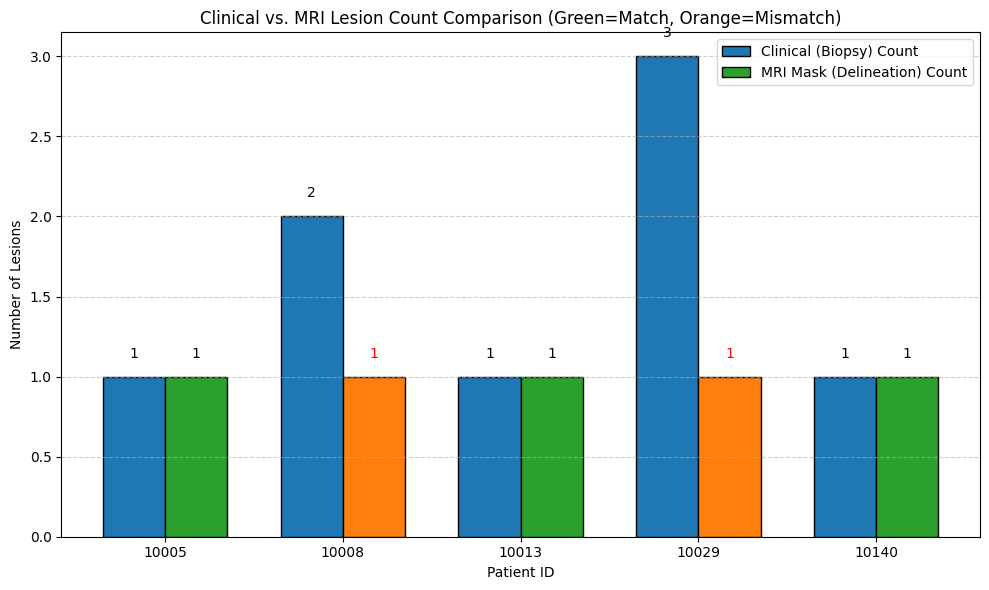


Plot generated showing the clinical vs. actual MRI lesion counts.


In [50]:
# Execute the pipeline
run_validation_pipeline()

This suggests that the radiologist who created the mask grouped all three biopsied lesions into a single contiguous region of interest (ROI) or labeled multiple distinct lesions with the same ID.

In [13]:
!pwd

/user/brussel/114/vsc11434/thesis


In [ ]:
from ipywidgets import interact, fixed
    def _plot_2D(arr, title, cmap, slice_nr):
        plt.imshow(arr[slice_nr], cmap=cmap)
        if title:
            plt.title(title)
        plt.xticks([]), plt.yticks([])
        plt.show()

## WEEK 2

### 3D INSTANCES/PATCHES EXTRACTION AND VISUALIZATION

In [7]:
import os
import SimpleITK as sitk
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

####  Visualizing the T2W IMAGE Overlay with Whole Gland Anatomical Delineation using Bosma22b AI 

In [8]:
def visualize_t2w_with_mask(t2w_path, mask_path, out_dir=None, show=True, save=True):
    # Read
    t2 = sitk.ReadImage(t2w_path)
    msk = sitk.ReadImage(mask_path)

    # Resample mask if geometry differs
    if (t2.GetSize()!=msk.GetSize()) or (t2.GetSpacing()!=msk.GetSpacing()) or (t2.GetDirection()!=msk.GetDirection()):
        rs = sitk.ResampleImageFilter()
        rs.SetReferenceImage(t2)
        rs.SetInterpolator(sitk.sitkNearestNeighbor)
        rs.SetOutputPixelType(sitk.sitkUInt8)
        rs.SetTransform(sitk.Transform())
        rs.SetDefaultPixelValue(0)
        msk = rs.Execute(msk)

    # Convert to numpy
    t2_np  = sitk.GetArrayFromImage(t2)
    msk_np = sitk.GetArrayFromImage(msk).astype(np.uint8)

    # Middle slice
    z = t2_np.shape[0] // 2

    # Display
    if show:
        plt.figure(figsize=(5,5))
        plt.imshow(t2_np[z], cmap="gray")
        plt.contour(msk_np[z], levels=[0.5], linewidths=1.5, colors="red")
        plt.axis("off")
        plt.show()

    # Save PNG
    if save:
        out_dir = out_dir or os.path.dirname(t2w_path)
        os.makedirs(out_dir, exist_ok=True)
        stem = os.path.basename(t2w_path).replace("_t2w.mha","").replace(".mha","").replace(".nii.gz","")
        out_png = os.path.join(out_dir, f"{stem}_overlay.png")
        plt.imsave(out_png, t2_np[z], cmap="gray")
        print(f"✅ Saved overlay: {out_png}")

    return t2_np, msk_np

In [9]:
#Checking the path for various directories
CASE = "10000"
DATA_ROOT = "/data/brussel/114/vsc11434/picai_raw/picai_public_images_fold0"
MASK_ROOT = "/user/brussel/114/vsc11434/thesis/picai_labels/anatomical_delineations/whole_gland/AI/Bosma22b"
OUT_DIR   = "/user/brussel/114/vsc11434/thesis/out_previews"

T2W  = f"{DATA_ROOT}/{CASE}/{CASE}_1000000_t2w.mha"
MASK = f"{MASK_ROOT}/{CASE}_1000000.nii.gz"

print(T2W)
print(MASK)

/data/brussel/114/vsc11434/picai_raw/picai_public_images_fold0/10000/10000_1000000_t2w.mha
/user/brussel/114/vsc11434/thesis/picai_labels/anatomical_delineations/whole_gland/AI/Bosma22b/10000_1000000.nii.gz


In [10]:
#Checking the coordinates of the voxels
try_dir = 'picai_labels/anatomical_delineations/whole_gland/AI/Bosma22b/10000_1000000.nii.gz'
read_image= sitk.ReadImage(try_dir)
data_np =  sitk.GetArrayFromImage(read_image).astype(np.uint8)
coords = np.argwhere(data_np > 0)
x,y,z = coords[0]
print(x,y,z)

8 304 277


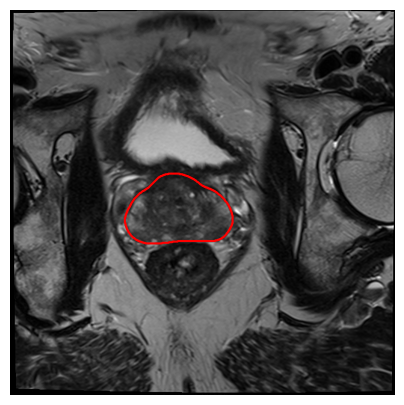

✅ Saved overlay: /user/brussel/114/vsc11434/thesis/out_previews/10000_1000000_overlay.png


In [11]:
visualize_t2w_with_mask(T2W, MASK, out_dir=OUT_DIR);

In [12]:
CASE = "10029"
DATA_ROOT = "/data/brussel/114/vsc11434/picai_raw/picai_public_images_fold0"
MASK_ROOT = "/user/brussel/114/vsc11434/thesis/picai_labels/anatomical_delineations/whole_gland/AI/Bosma22b"
OUT_DIR   = "/user/brussel/114/vsc11434/thesis/out_previews"

T2W_2  = f"{DATA_ROOT}/{CASE}/{CASE}_1000029_t2w.mha"
MASK_2 = f"{MASK_ROOT}/{CASE}_1000029.nii.gz"

print(T2W_2)
print(MASK_2)

/data/brussel/114/vsc11434/picai_raw/picai_public_images_fold0/10029/10029_1000029_t2w.mha
/user/brussel/114/vsc11434/thesis/picai_labels/anatomical_delineations/whole_gland/AI/Bosma22b/10029_1000029.nii.gz


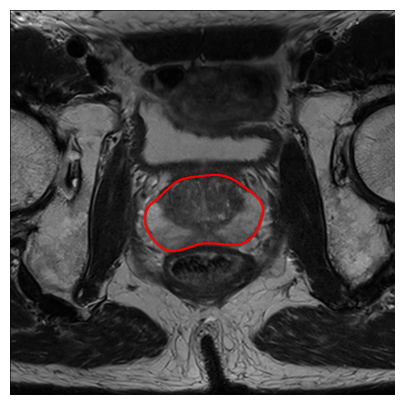

✅ Saved overlay: /user/brussel/114/vsc11434/thesis/out_previews/10029_1000029_overlay.png


In [13]:
visualize_t2w_with_mask(T2W_2, MASK_2, out_dir=OUT_DIR);

### Extracting only the Gland

Original shape: (19, 640, 640)
Cropped shape: (10, 131, 198)


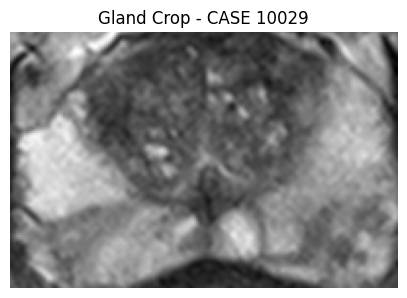

In [14]:
CASE = "10029" # for patient 
DATA_ROOT = "/data/brussel/114/vsc11434/picai_raw/picai_public_images_fold0"
MASK_ROOT = "/user/brussel/114/vsc11434/thesis/picai_labels/anatomical_delineations/whole_gland/AI/Bosma22b"
OUT_DIR   = "/user/brussel/114/vsc11434/thesis/out_previews"

T2W_2  = f"{DATA_ROOT}/{CASE}/{CASE}_1000029_t2w.mha"
MASK_2 = f"{MASK_ROOT}/{CASE}_1000029.nii.gz"

 # Load volumes
t2 = sitk.ReadImage(T2W_2 )
msk = sitk.ReadImage(MASK_2)


# --- Resample mask to T2 geometry if needed ---
if (t2.GetSize()!=msk.GetSize()) or (t2.GetSpacing()!=msk.GetSpacing()) or (t2.GetDirection()!=msk.GetDirection()):
    rs = sitk.ResampleImageFilter()
    rs.SetReferenceImage(t2)
    rs.SetInterpolator(sitk.sitkNearestNeighbor)
    rs.SetOutputPixelType(sitk.sitkUInt8)
    msk = rs.Execute(msk)

# --- Convert to numpy (z,y,x) ---
t2_np = sitk.GetArrayFromImage(t2)
msk_np = sitk.GetArrayFromImage(msk)

# --- Compute bounding box of prostate gland ---
z, y, x = np.where(msk_np > 0)
zmin, zmax = z.min(), z.max()
ymin, ymax = y.min(), y.max()
xmin, xmax = x.min(), x.max()

# --- Crop gland ---
t2_crop = t2_np[zmin:zmax, ymin:ymax, xmin:xmax]
msk_crop = msk_np[zmin:zmax, ymin:ymax, xmin:xmax]

print("Original shape:", t2_np.shape)
print("Cropped shape:", t2_crop.shape)

# --- Visualize center slice of cropped gland ---
z_mid = t2_crop.shape[0] // 2

plt.figure(figsize=(5,5))
plt.imshow(t2_crop[z_mid], cmap="gray")
plt.title(f"Gland Crop - CASE {CASE}")
plt.axis("off")
plt.show()

### Defining the Instance Extraction 

In [15]:
def extract_patches_for_case(t2w_path, mask_path, out_dir, patch_size=16, num_patches=150):
    """
    Extract 3D patches from inside the prostate gland.
    Saves patches as .npy files inside out_dir.
    """

    os.makedirs(out_dir, exist_ok=True)

    # Load volumes
    t2 = sitk.ReadImage(t2w_path)
    msk = sitk.ReadImage(mask_path)

    # Convert → numpy in (z,y,x)
    t2_np  = sitk.GetArrayFromImage(t2)
    msk_np = sitk.GetArrayFromImage(msk)

    # Coordinates where mask = 1
    coords = np.argwhere(msk_np > 0)

    patches_saved = 0
    half = patch_size // 2

    while patches_saved < num_patches:
        # Choose random voxel inside gland
        z, y, x = coords[np.random.randint(len(coords))]

        # Compute box limits
        z0, z1 = z-half, z+half
        y0, y1 = y-half, y+half
        x0, x1 = x-half, x+half

        # Skip if patch would go out-of-bounds
        if z0 < 0 or y0 < 0 or x0 < 0:
            continue
        if z1 >= t2_np.shape[0] or y1 >= t2_np.shape[1] or x1 >= t2_np.shape[2]:
            continue

        patch = t2_np[z0:z1, y0:y1, x0:x1]

        # Save single patch
        out_path = os.path.join(out_dir, f"patch_{patches_saved:03d}.npy")
        np.save(out_path, patch)
        patches_saved += 1

    print(f"✅ Saved {patches_saved} patches to {out_dir}")


In [133]:
!{sys.executable} -m pip install --user tqdm

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: pip install --upgrade pip


### Running the Function to extract to Scratch Directory

In [143]:
from tqdm import tqdm

t2w_path = "/data/brussel/114/vsc11434/picai_raw/picai_public_images_fold0"
mask_path = "picai_labels/anatomical_delineations/whole_gland/AI/Bosma22b"
INSTANCES_ROOT = "/scratch/brussel/114/vsc11434/picai_instances"
PROCESSED_ROOT = "/scratch/brussel/114/vsc11434/picai_processed"


os.makedirs(INSTANCES_ROOT, exist_ok=True)

manifest = pd.read_csv("marksheet.csv")

for _, row in tqdm(manifest.iterrows(),desc="Patching Extraction"):
    
    case_id = row["patient_id"]
    study_id = row["study_id"]
    image_path = f"/data/brussel/114/vsc11434/picai_raw/picai_public_images_fold0/{case_id}"
    t2w_path = Path(image_path)
    if t2w_path.exists():
        t2w_path = Path(glob(image_path+"/*_t2w.mha")[0])
        mask_path = Path(f"picai_labels/anatomical_delineations/whole_gland/AI/Bosma22b/{case_id}_{study_id}.nii.gz")
        if mask_path.exists():
            out_dir = f"{INSTANCES_ROOT}/{case_id}"
            extract_patches_for_case(t2w_path, mask_path, out_dir, patch_size=16, num_patches=150)
        else:
            print("Path No found")
    else:
        continue

Patching Extraction: 1it [00:00,  1.64it/s]

✅ Saved 150 patches to /scratch/brussel/114/vsc11434/picai_instances/10000


Patching Extraction: 2it [00:00,  2.10it/s]

✅ Saved 150 patches to /scratch/brussel/114/vsc11434/picai_instances/10001


Patching Extraction: 4it [00:01,  3.65it/s]

✅ Saved 150 patches to /scratch/brussel/114/vsc11434/picai_instances/10003


... (588 outputs left out)

Patching Extraction: 1498it [07:31,  8.06it/s]

✅ Saved 150 patches to /scratch/brussel/114/vsc11434/picai_instances/11473


Patching Extraction: 1500it [07:31,  3.32it/s]

✅ Saved 150 patches to /scratch/brussel/114/vsc11434/picai_instances/11474


### Visualizing some of the instances for specific patient

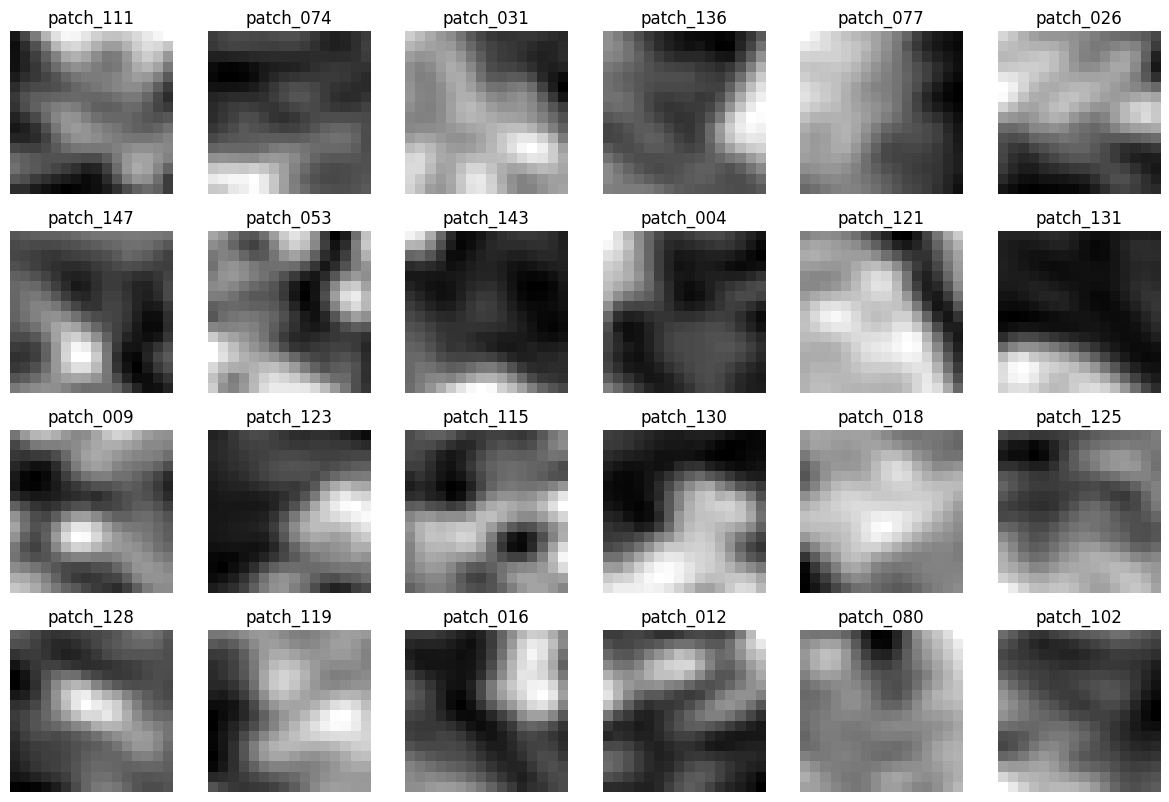

Display 24 patches for patient 10000


In [33]:
#Visualizing the some instances 
import random

instances_id= "10000"
instances_dir = Path("/scratch/brussel/114/vsc11434/picai_instances") / instances_id

number_to_visualize = 24

if not instances_dir.exists():
    print(f"No patches found for patient {instances_id}")
else:
    patch_files = list(instances_dir.glob("*.npy"))
    
    if len(patch_files) ==0:
        print("No .npy patch files found in directory")
    else:
        #Select randomly to visualize
        patch_files = random.sample(patch_files,min(number_to_visualize, len(patch_files)))
        cols = 6
        rows = (len(patch_files) + cols - 1) 
        plt.figure(figsize=(12,rows*2))
        for i, patch_path in enumerate(patch_files):
            patch = np.load(patch_path)
            #show the center slice
            mid = patch.shape[0] // 2
            patch_slice = patch[mid]

            plt.subplot(rows, cols, i + 1)
            plt.imshow(patch_slice, cmap="gray")
            plt.title(patch_path.name.replace(".npy",""))
            plt.axis("off")
        plt.tight_layout()
        plt.show()
        print(f"Display {len(patch_files)} patches for patient {instances_id}")

# WEEK 2 REPEAT 

In [16]:
import os,json
from math import ceil

In [ ]:
def _sitk_to_numpy(img):
    """Return numpy array (z,y,x) and spacing in same order (sz,sy,sx)."""
    # arr_read = sitk.ReadImage(img)
    arr = sitk.GetArrayFromImage(img)              #(z,y,x) Convert SimpleITK image → NumPy array
    sx, sy, sz =  img.GetSpacing()                 # SITK gives (x,y,z): Returns the physical spacing units (mm)
    return arr, (sz, sy, sx)         #return the spacing reordered to match the array axes

In [ ]:
t2_path = 'Dataset/10000/10000_1000000_t2w.mha'

array_print, (sz,sy,sx)  = _sitk_to_numpy(t2_path)
print(array_print.shape[0]*sz)



In [18]:
def _resample_mask_if_needed(t2_img, msk_img):
    """Ensures that mask and t2w mri align perfectly in space"""
    if (t2_img.GetSize() != msk_img.GetSize()) or \  #check whether mask and t2w match the same geometry
       (t2_img.GetSpacing() != msk_img.GetSpacing()) or \
       (t2_img.GetDirection()!= msk_img.GetDirection()):
        rs = sitk.ResampleImageFilter()  #create a resample filter
        rs.SetReferenceImage(t2_img)  #we use the t2w image as the reference 
        rs.SetInterpolator(sitk.sitkNearestNeighbor) #we choose interpolation type
        rs.SetOutputPixelType(sitk.sitkUInt8) #ensure the resampled mask stays binary
        return rs.Execute(msk_img) # execute the resampling
    return msk_img #if no resampling reqquired, return original mask

In [20]:
def _valid_patch_bounds(center_zyx, half_zyx, vol_shape):
    """We create a bound to prevent patches from going outside the prostate image"""
    z,y,x = center_zyx   #unpack the center coordinate
    hz,hy,hx = half_zyx #unpack half patch size
    z0,z1 = z-hz, z+hz  #compute bounding box corners
    y0,y1 = y-hy, y+hy
    x0,x1 = x-hx, x+hx
    if z0 < 0 or y0 < 0 or x0 < 0: return None #we check if the bounds go outside image on the negative side
    if z1 > vol_shape[0] or y1 > vol_shape[1] or x1 > vol_shape[2]: return None #we also check upper bounds
    return (z0,z1,y0,y1,x0,x1) #return usable slice indices if valid


In [25]:
def _uniform_grid_centers(mask, patch_size_vox=(16,16,16), stride_vox=None, cov_thresh=0.6):
    """
    Build even-spaced centers across the gland.
    Keep centers only if the patch has enough gland coverage.
    """
    Z,Y,X = mask.shape #get volume dimensions
    #patch and we half-patch sizes
    pz,py,px = patch_size_vox 
    half = (pz//2, py//2, px//2)

    # we set stride with ~50% overlap (thus half patch size)
    if stride_vox is None:
        stride_vox = (max(1,pz//2), max(1,py//2), max(1,px//2))
    sz,sy,sx = stride_vox

    #Generate candidate patch center coordinates
    #Creates a 3D grid of center positions inside the volume
    cz = np.arange(half[0], Z-half[0]+1, sz, dtype=int)
    cy = np.arange(half[1], Y-half[1]+1, sy, dtype=int)
    cx = np.arange(half[2], X-half[2]+1, sx, dtype=int)

    centers = []

    #Loop through all candidate centers
    for z in cz:
        for y in cy:
            for x in cx:
                b = _valid_patch_bounds((z,y,x), half, mask.shape) #call the valid bound function
                if b is None: continue
                z0,z1,y0,y1,x0,x1 = b
                cov = mask[z0:z1, y0:y1, x0:x1].mean() #compute gland coverage inside the patch
                if cov >= cov_thresh: #we keep only meaningful patches (at least 60% of prostrate tissue) 
                    centers.append((z,y,x))
    return np.array(centers, dtype=int) #return the final list of patch centers


In [27]:
def _target_patches_from_volume(mask, spacing_zyx, density_per_cc=2.0, min_patches=64, max_patches=512):
    """
    Determines how many patches to extract based on how large the gland is 
    patches = density_per_cc * gland_volume_cc, then clamped
    """
    vox_in_mask = (mask > 0).sum() #count many voxels belong to the gland
    gland_mm3 = vox_in_mask * (spacing_zyx[0]*spacing_zyx[1]*spacing_zyx[2])   # convert to physical gland vloumne (mm^3)
    gland_cc = gland_mm3 / 1000.0
    target = int(np.clip(ceil(density_per_cc * gland_cc), min_patches, max_patches))
    return target, gland_cc

In [28]:
def extract_patches_uniform(
    t2w_path, mask_path, out_dir,
    patch_size_vox=(16,16,16),
    stride_vox=None,              # default ~50% overlap
    density_per_cc=2.0,           # simple size-aware rule
    min_patches=64, max_patches=512,
    coverage_thresh=0.6,
    seed=0
):
    """
    Simple, size-aware, uniform-coverage 3D patch extractor.
    - Even grid across gland
    - Patch count scales with gland volume (cc)
    - Keeps patches with >= coverage_thresh gland voxels
    - If too many candidates: downsample evenly
    - Saves .npy patches + sampling_meta.json
    """
    rng = np.random.default_rng(seed)
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)

    # Load images
    t2_img = sitk.ReadImage(str(t2w_path))
    msk_img = sitk.ReadImage(str(mask_path))
    msk_img = _resample_mask_if_needed(t2_img, msk_img)

    vol, sp_zyx = _sitk_to_numpy(t2_img)    # (z,y,x) + spacing in mm (z,y,x)
    mask, _     = _sitk_to_numpy(msk_img)
    mask = (mask > 0).astype(np.uint8)

    # 1) size-aware target patches
    target, gland_cc = _target_patches_from_volume(mask, sp_zyx, density_per_cc, min_patches, max_patches)

    # 2) uniform grid of candidate centers (coverage-checked)
    cand = _uniform_grid_centers(mask, patch_size_vox, stride_vox, cov_thresh=coverage_thresh)

    # 3) if too many candidates, take an even subset
    #    pick indices spaced across the list to preserve uniformity
    if len(cand) > target:
        idx = np.linspace(0, len(cand)-1, num=target, dtype=int)
        chosen = cand[idx]
    else:
        # 4) not enough? top up with random valid centers inside gland (rare)
        chosen = cand.copy()
        half = (patch_size_vox[0]//2, patch_size_vox[1]//2, patch_size_vox[2]//2)
        coords = np.argwhere(mask > 0)
        tries = 0
        while len(chosen) < target and tries < 100000:
            tries += 1
            z,y,x = coords[rng.integers(0, len(coords))]
            b = _valid_patch_bounds((z,y,x), half, mask.shape)
            if b is None: continue
            z0,z1,y0,y1,x0,x1 = b
            if mask[z0:z1,y0:y1,x0:x1].mean() < coverage_thresh: continue
            chosen = np.vstack([chosen, [z,y,x]]) if len(chosen) else np.array([[z,y,x]])

    # 5) save patches
    half = (patch_size_vox[0]//2, patch_size_vox[1]//2, patch_size_vox[2]//2)
    saved = 0
    for i,(z,y,x) in enumerate(chosen):
        b = _valid_patch_bounds((z,y,x), half, vol.shape)
        if b is None: continue
        z0,z1,y0,y1,x0,x1 = b
        patch = vol[z0:z1, y0:y1, x0:x1].astype(np.float32)
        np.save(out_dir / f"patch_{i:04d}.npy", patch)
        saved += 1

    meta = {
        "t2w_path": str(t2w_path),
        "mask_path": str(mask_path),
        "spacing_mm_zyx": sp_zyx,
        "patch_size_vox": patch_size_vox,
        "stride_vox": stride_vox if stride_vox else (patch_size_vox[0]//2, patch_size_vox[1]//2, patch_size_vox[2]//2),
        "coverage_thresh": coverage_thresh,
        "density_per_cc": density_per_cc, "min_patches": min_patches, "max_patches": max_patches,
        "gland_volume_cc": gland_cc, "target_patches": int(target), "saved_patches": int(saved),
        "seed": int(seed)
    }
    with open(out_dir / "sampling_meta.json", "w") as f:
        json.dump(meta, f, indent=2)

    print(f"✅ Saved {saved} patches → {out_dir}  (target={target}, gland={gland_cc:.2f} cc)")

In [17]:
from glob import glob
import pandas as pd
from pathlib import Path
from tqdm import tqdm

INSTANCES_ROOT = "/scratch/brussel/114/vsc11434/uniform_instances"
manifest = pd.read_csv("marksheet.csv")  # for patient_id, study_id

for _, row in tqdm(manifest.iterrows(), total=len(manifest), desc="Uniform size-aware patching"):
    case_id  = str(row["patient_id"])
    study_id = str(row["study_id"])

    img_dir = f"/data/brussel/114/vsc11434/picai_raw/picai_public_images_fold0/{case_id}"
    t2_candidates = glob(img_dir + "/*_t2w.mha")
    if not t2_candidates:
        print(f"no T2W for {case_id}")
        continue

    t2w_path = Path(t2_candidates[0])
    mask_path = Path(f"/user/brussel/114/vsc11434/thesis/picai_labels/anatomical_delineations/whole_gland/AI/Bosma22b/{case_id}_{study_id}.nii.gz")
    if not mask_path.exists():
        print(f"no MASK for {case_id}_{study_id}")
        continue

    out_dir = Path(INSTANCES_ROOT) / case_id
    extract_patches_uniform(
        t2w_path, mask_path, out_dir,
        patch_size_vox=(16,16,16),
        stride_vox=None,          
        density_per_cc=2.0,       
        min_patches=64, max_patches=512,
        coverage_thresh=0.6,
        seed=2025
    )


Uniform size-aware patching:   0%|          | 1/1500 [00:00<20:31,  1.22it/s]

✅ Saved 72 patches → /scratch/brussel/114/vsc11434/uniform_instances/10000  (target=72, gland=35.71 cc)


Uniform size-aware patching:   0%|          | 2/1500 [00:01<19:30,  1.28it/s]

✅ Saved 180 patches → /scratch/brussel/114/vsc11434/uniform_instances/10001  (target=180, gland=89.67 cc)
no T2W for 10002


Uniform size-aware patching:   0%|          | 4/1500 [00:02<10:49,  2.30it/s]

✅ Saved 145 patches → /scratch/brussel/114/vsc11434/uniform_instances/10003  (target=145, gland=72.42 cc)
no T2W for 10004
no T2W for 10005


... (570 outputs left out)

Uniform size-aware patching: 100%|█████████▉| 1498/1500 [04:27<00:00,  6.70it/s]

✅ Saved 143 patches → /scratch/brussel/114/vsc11434/uniform_instances/11473  (target=143, gland=71.05 cc)


Uniform size-aware patching: 100%|██████████| 1500/1500 [04:27<00:00,  5.60it/s]

✅ Saved 149 patches → /scratch/brussel/114/vsc11434/uniform_instances/11474  (target=149, gland=74.30 cc)
no T2W for 11475


In [38]:
def _qc_patient(patient_id, instances_root="/scratch/brussel/114/vsc11434/uniform_instances",
                      n_random=12, n_textured=12):
    case_dir = Path(instances_root) / str(patient_id)
    meta_path = case_dir / "sampling_meta.json"

    if not meta_path.exists():
        print(f" No sampling_meta.json for patient {patient_id}")
        return
    
    # --- Load meta + original T2W + mask ---
    with open(meta_path) as f:
        meta = json.load(f)

    t2 = sitk.ReadImage(meta["t2w_path"])
    mask = sitk.ReadImage(meta["mask_path"])
    t2_np = sitk.GetArrayFromImage(t2)                 # (z,y,x)
    mask_np = sitk.GetArrayFromImage(mask).astype(bool)

    # Show mid-gland slice 
    mid = int(np.argmax(mask_np.sum(axis=(1,2))))      # slice with largest gland area
    plt.figure(figsize=(6,6))
    plt.imshow(t2_np[mid], cmap="gray")
    plt.contour(mask_np[mid], colors="red", linewidths=1)
    plt.title(f"Patient {patient_id} — mid-gland T2W + mask")
    plt.axis("off")
    plt.show()

    # --- Load all patches ---
    patch_files = sorted(case_dir.glob("patch_*.npy"))
    if not patch_files:
        print(f" No patches (.npy) found for patient {patient_id}")
        return

    # Pre-compute simple stats for each patch (mean, std) + keep center slice
    patches = []
    for p in patch_files:
        arr = np.load(p)
        mid_z = arr.shape[0] // 2
        center_slice = arr[mid_z]
        patches.append({
            "path": p,
            "slice": center_slice,
            "mean": float(center_slice.mean()),
            "std": float(center_slice.std()),
        })

    #  Random patch gallery
    rand_patches = random.sample(patches, min(n_random, len(patches)))
    cols = 6
    rows = (len(rand_patches) + cols - 1) // cols

    plt.figure(figsize=(12, rows * 2))
    for i, info in enumerate(rand_patches):
        plt.subplot(rows, cols, i+1)
        plt.imshow(info["slice"], cmap="gray")
        plt.title(info["path"].name.replace(".npy",""))
        plt.axis("off")
    plt.suptitle(f"Patient {patient_id} — random patches")
    plt.tight_layout()
    plt.show()

    #  High-texture patch gallery 
    sorted_by_std = sorted(patches, key=lambda x: x["std"], reverse=True)
    hi_tex = sorted_by_std[:min(n_textured, len(sorted_by_std))]
    cols = 6
    rows = (len(hi_tex) + cols - 1) // cols

    plt.figure(figsize=(12, rows * 2))
    for i, info in enumerate(hi_tex):
        plt.subplot(rows, cols, i+1)
        plt.imshow(info["slice"], cmap="gray")
        plt.title(f"{info['path'].name}\nstd={info['std']:.2f}")
        plt.axis("off")
    plt.suptitle(f"Patient {patient_id} — high-texture patches")
    plt.tight_layout()
    plt.show()

    print(f" QC done for patient {patient_id}: {len(patch_files)} patches total.")

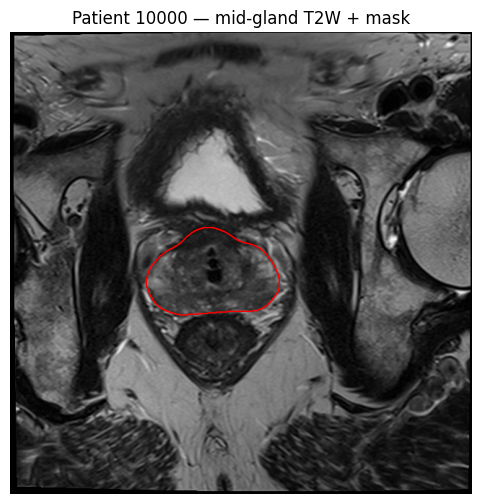

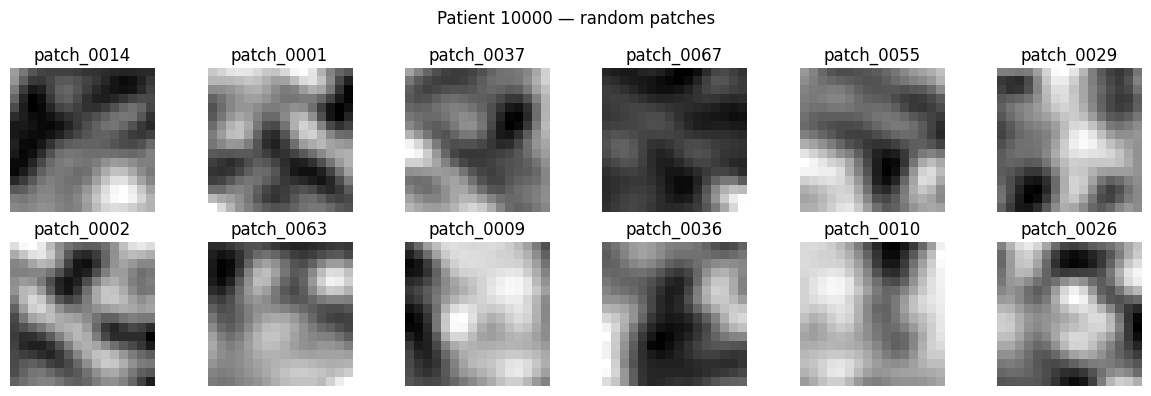

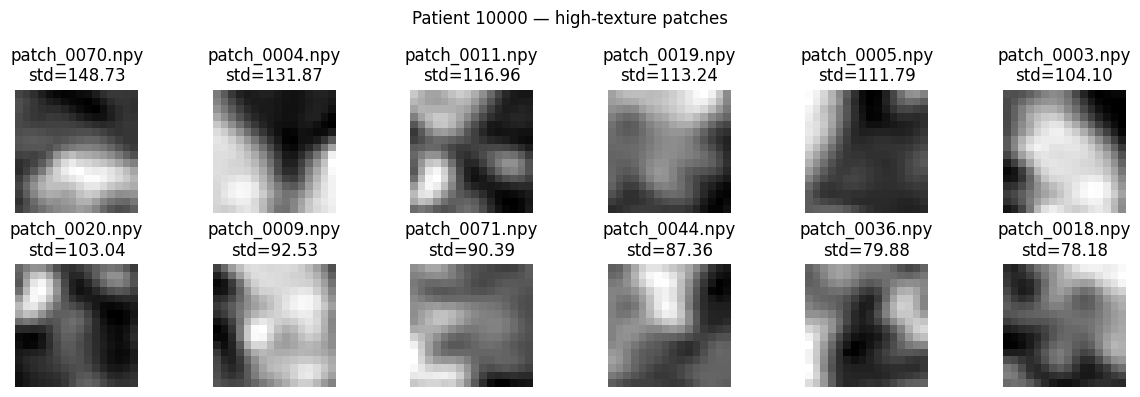

 QC done for patient 10000: 72 patches total.


In [39]:
_qc_patient("10000")

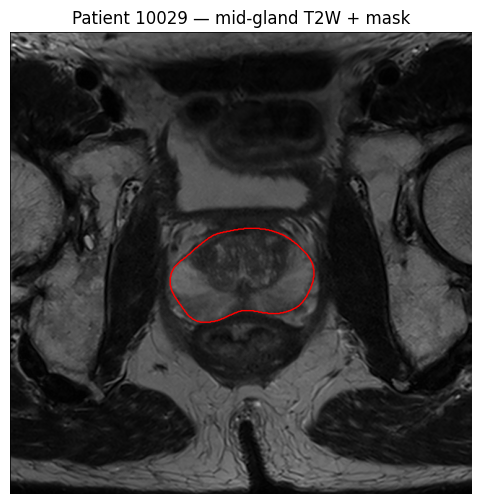

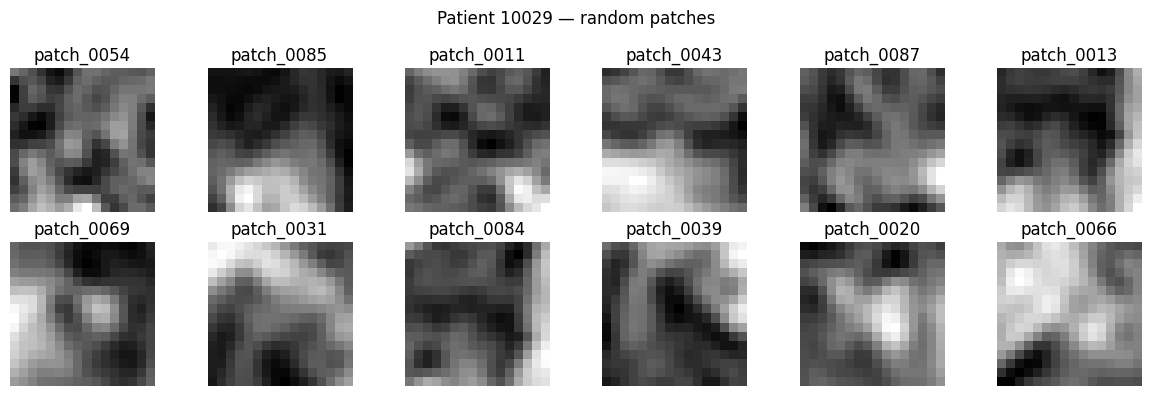

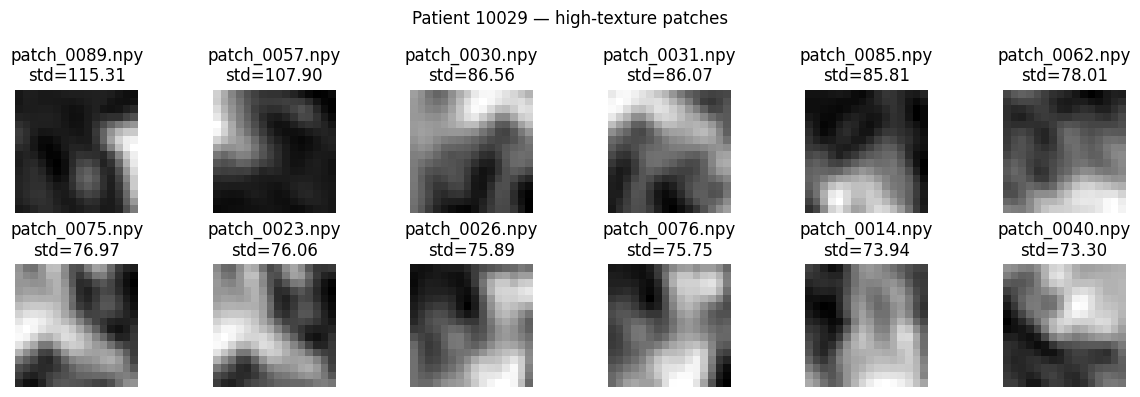

 QC done for patient 10029: 90 patches total.


In [41]:
_qc_patient("10029")

In [44]:
def _resample_to_ref(ref_img, mov_img, out_type=sitk.sitkUInt8):
    """Resample mask (mov_img) to reference image (ref_img) with nearest neighbor."""
    if (ref_img.GetSize()    == mov_img.GetSize() and
        ref_img.GetSpacing() == mov_img.GetSpacing() and
        ref_img.GetDirection()== mov_img.GetDirection()):
        return mov_img
    rs = sitk.ResampleImageFilter()
    rs.SetReferenceImage(ref_img)
    rs.SetInterpolator(sitk.sitkNearestNeighbor)
    rs.SetOutputPixelType(out_type)
    return rs.Execute(mov_img)

def show_t2_gland_lesion(case_id="10029", study_id="1000029"):
    # ---- paths ----
    t2_path   = f"/data/brussel/114/vsc11434/picai_raw/picai_public_images_fold0/{case_id}/{case_id}_{study_id}_t2w.mha"
    gland_path = f"/user/brussel/114/vsc11434/thesis/picai_labels/anatomical_delineations/whole_gland/AI/Bosma22b/{case_id}_{study_id}.nii.gz"
    lesion_path = f"/user/brussel/114/vsc11434/thesis/picai_labels/csPCa_lesion_delineations/human_expert/Pooch25/{case_id}_{study_id}.nii.gz"

    t2_file = Path(t2_path)
    gland_file = Path(gland_path)
    lesion_file = Path(lesion_path)

    if not t2_file.exists():
        print("T2W not found:", t2_file)
        return
    if not gland_file.exists():
        print("Gland mask not found:", gland_file)
        return
    if not lesion_file.exists():
        print("Lesion mask not found:", lesion_file)
        return

    # ---- load images ----
    t2_img     = sitk.ReadImage(str(t2_file))
    gland_img  = sitk.ReadImage(str(gland_file))
    lesion_img = sitk.ReadImage(str(lesion_file))

    # ---- resample masks to T2 geometry (if needed) ----
    gland_img_rs  = _resample_to_ref(t2_img, gland_img, out_type=sitk.sitkUInt8)
    lesion_img_rs = _resample_to_ref(t2_img, lesion_img, out_type=sitk.sitkUInt8)

    t2_np     = sitk.GetArrayFromImage(t2_img)          # (z,y,x)
    gland_np  = sitk.GetArrayFromImage(gland_img_rs)>0
    lesion_np = sitk.GetArrayFromImage(lesion_img_rs)>0

    # ---- choose slice with max lesion area ----
    if lesion_np.sum() == 0:
        print("Lesion mask is empty, showing mid-gland instead.")
        z_idx = int(np.argmax(gland_np.sum(axis=(1,2))))
    else:
        z_idx = int(np.argmax(lesion_np.sum(axis=(1,2))))

    # ---- plot ----
    plt.figure(figsize=(6,6))
    plt.imshow(t2_np[z_idx], cmap="gray")
    # whole gland in red
    plt.contour(gland_np[z_idx], colors="red", linewidths=1.0)
    # lesion in yellow
    plt.contour(lesion_np[z_idx], colors="yellow", linewidths=1.5)
    plt.title(f"Case {case_id}_{study_id} — T2W + gland (red) + lesion (yellow), slice {z_idx}")
    plt.axis("off")
    plt.show()

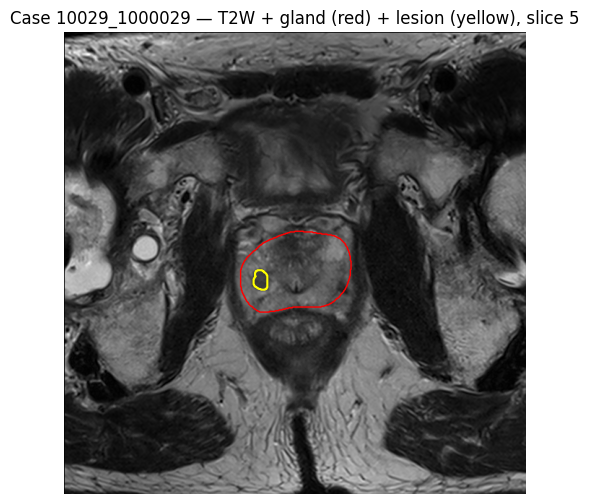

In [45]:
show_t2_gland_lesion(case_id="10029", study_id="1000029")

#### References

https://gist.github.com/mrajchl/ccbd5ed12eb68e0c1afc5da116af614a

https://stackoverflow.com/questions/78855966/resampling-mr-image-using-sitk-resampleimagefilter-and-a-composite-transform-r

https://docs.itk.org/projects/doxygen/en/stable/classitk_1_1ResampleImageFilter.html

https://proceedings.mlr.press/v172/redekop22a/redekop22a.pdf

https://insightsoftwareconsortium.github.io/SimpleITK-Notebooks/Python_html/21_Transforms_and_Resampling.html

https://github.com/tqdm/tqdm

https://numpy.org/doc/stable/reference/generated/numpy.argwhere.html


https://www.youtube.com/watch?v=YBA-OST6t6E